# DS605: Fundamentals of Machine Learning
## Lab Assignment 8: Decision Trees and Support Vector Machines

**Dataset:** UCI Banknote Authentication Dataset  
**Features:** Variance, Skewness, Curtosis, Entropy (Binary Classification: 0 vs 1)  
**Workflow:**
1. Data Loading and Preprocessing
2. **Part A:** Decision Tree from Scratch (Gini/Entropy, Tree Building, Visualizations, Comparisons)
3. **Part B:** Linear SVM from Scratch (Subgradient Descent, Margins, Violations, Hyperparameters)
4. **Part C:** Kernel SVM and Nonlinear Boundaries (`make_moons` with Linear, Poly, RBF Kernels)
5. **Part D:** Final Full 4-Feature Benchmark & Comprehensive Analysis

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

np.random.seed(42)

## 1. Dataset Loading and Preparation

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
column_names = ['variance', 'skewness', 'curtosis', 'entropy', 'class']

try:
    df = pd.read_csv(url, header=None, names=column_names)
except Exception as e:
    print("Network error downloading dataset, generating local synthetic replica: ", e)
    from sklearn.datasets import make_classification
    X_syn, y_syn = make_classification(n_samples=1372, n_features=4, n_informative=4, n_redundant=0, random_state=42)
    df = pd.DataFrame(X_syn, columns=column_names[:4])
    df['class'] = y_syn

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (1372, 5)
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0


--- 
## Part A - Decision Tree from Scratch

- Implement Gini impurity and Entropy.
- Implement recursive splitting and tree construction with stopping rules (`max_depth`, `min_samples_split`).
- Visualize tree structure and compare decision boundaries with Scikit-learn.

In [3]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    @property
    def is_leaf(self):
        return self.value is not None

class ScratchDecisionTreeClassifier:
    def __init__(self, criterion='gini', max_depth=5, min_samples_split=2):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _impurity(self, y):
        if len(y) == 0:
            return 0.0
        p1 = np.mean(y == 1)
        p0 = 1.0 - p1
        if self.criterion == 'gini':
            return 1.0 - (p0**2 + p1**2)
        elif self.criterion == 'entropy':
            eps = 1e-15
            ent = 0.0
            for p in (p0, p1):
                if p > 0:
                    ent -= p * np.log2(p + eps)
            return ent
        else:
            raise ValueError("Criterion must be 'gini' or 'entropy'")

    def _best_split(self, X, y):
        best_gain = -1.0
        split_idx, split_thresh = None, None
        current_impurity = self._impurity(y)
        n_samples, n_features = X.shape

        for feat_idx in range(n_features):
            thresholds = np.unique(X[:, feat_idx])
            for thresh in thresholds:
                left_mask = X[:, feat_idx] <= thresh
                right_mask = ~left_mask

                if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
                    continue

                y_l, y_r = y[left_mask], y[right_mask]
                gain = current_impurity - (
                    (len(y_l) / n_samples) * self._impurity(y_l) +
                    (len(y_r) / n_samples) * self._impurity(y_r)
                )

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = thresh

        return split_idx, split_thresh, best_gain

    def _build_tree(self, X, y, depth=0):
        n_samples = len(y)
        n_labels = len(np.unique(y))

        # Stopping conditions
        if depth >= self.max_depth or n_labels <= 1 or n_samples < self.min_samples_split:
            leaf_val = int(np.round(np.mean(y))) if n_samples > 0 else 0
            return Node(value=leaf_val)

        feat_idx, thresh, gain = self._best_split(X, y)
        if gain <= 1e-7:
            return Node(value=int(np.round(np.mean(y))))

        left_mask = X[:, feat_idx] <= thresh
        left_child = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._build_tree(X[~left_mask], y[~left_mask], depth + 1)
        return Node(feature=feat_idx, threshold=thresh, left=left_child, right=right_child)

    def fit(self, X, y):
        self.root = self._build_tree(np.asarray(X), np.asarray(y))
        return self

    def _predict_one(self, node, x):
        if node.is_leaf:
            return node.value
        if x[node.feature] <= node.threshold:
            return self._predict_one(node.left, x)
        return self._predict_one(node.right, x)

    def predict(self, X):
        X = np.asarray(X)
        return np.array([self._predict_one(self.root, x) for x in X])

    def print_tree(self, node=None, indent="", feature_names=None):
        if node is None:
            node = self.root
        if node.is_leaf:
            print(f"{indent}-> Class: {node.value}")
            return
        name = feature_names[node.feature] if feature_names is not None else f"Feature {node.feature}"
        print(f"{indent}[{name} <= {node.threshold:.3f}]")
        print(f"{indent}  Left:")
        self.print_tree(node.left, indent + "    ", feature_names)
        print(f"{indent}  Right:")
        self.print_tree(node.right, indent + "    ", feature_names)

### Two-Feature Tree Comparison & Decision Boundary Plotting

=== Manual Tree Split Rules ===
[variance <= 0.759]
  Left:
    [skewness <= 5.202]
      Left:
        [variance <= 0.318]
          Left:
            -> Class: 1
          Right:
            -> Class: 1
      Right:
        [variance <= -4.148]
          Left:
            -> Class: 1
          Right:
            -> Class: 0
  Right:
    [variance <= 1.788]
      Left:
        [skewness <= 4.780]
          Left:
            -> Class: 0
          Right:
            -> Class: 0
      Right:
        [variance <= 2.392]
          Left:
            -> Class: 0
          Right:
            -> Class: 0


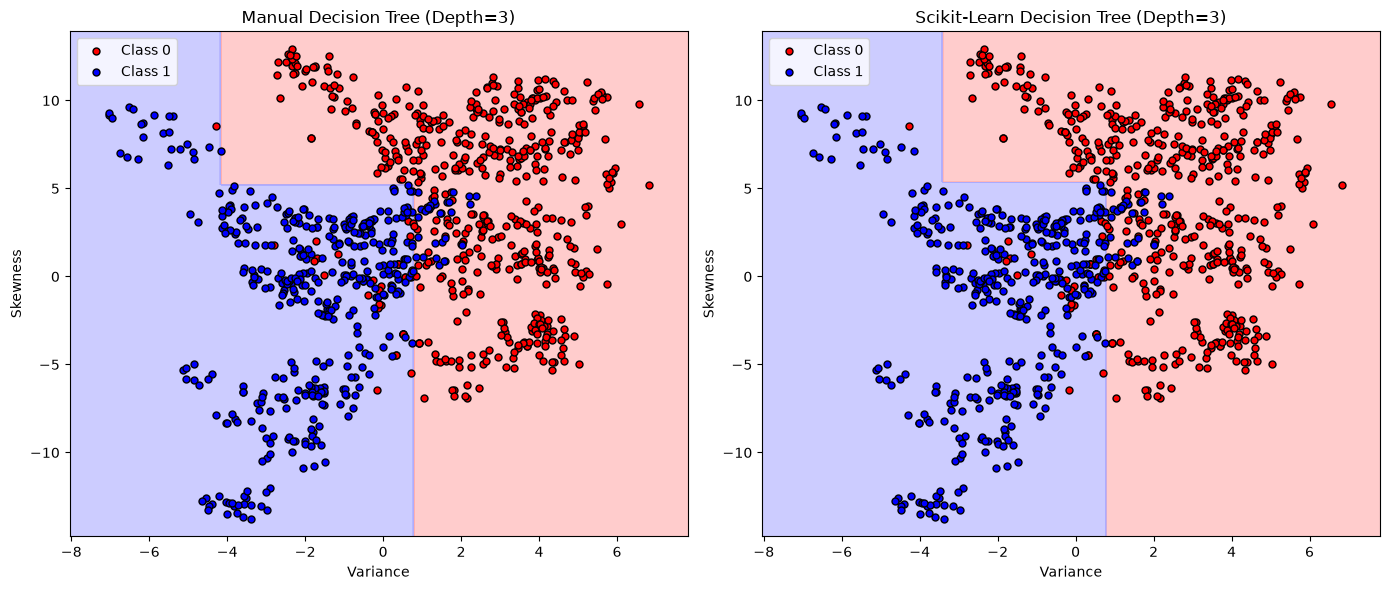

In [14]:
X_2d = df[['variance', 'skewness']].values
y = df['class'].values

X_train_2d, X_test_2d, y_train, y_test = train_test_split(
    X_2d, y, test_size=0.3, random_state=42, stratify=y
)

# Fit Scratch and Scikit-learn Trees
manual_tree = ScratchDecisionTreeClassifier(criterion='gini', max_depth=3)
manual_tree.fit(X_train_2d, y_train)

sk_tree = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
sk_tree.fit(X_train_2d, y_train)

print("=== Manual Tree Split Rules ===")
manual_tree.print_tree(feature_names=['variance', 'skewness'])

# Decision Boundary Plot Function
def plot_decision_boundary(clf, X, y, title, ax):
    h = 0.05
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
    cmap_bold = ['#FF0000', '#0000FF']
    
    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.6)
    for idx, c in enumerate(np.unique(y)):
        ax.scatter(X[y == c, 0], X[y == c, 1], label=f"Class {c}", c=cmap_bold[idx], edgecolors='k', s=25)
    ax.set_title(title)
    ax.set_xlabel('Variance')
    ax.set_ylabel('Skewness')
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_decision_boundary(manual_tree, X_train_2d, y_train, "Manual Decision Tree (Depth=3)", axes[0])
plot_decision_boundary(sk_tree, X_train_2d, y_train, "Scikit-Learn Decision Tree (Depth=3)", axes[1])
plt.tight_layout()
plt.show()

### Hyperparameter Exploration: Criterion and Max Depth

In [5]:
depths = [1, 2, 3, 5, 8]
criteria = ['gini', 'entropy']
results = []

for crit in criteria:
    for d in depths:
        m_tree = ScratchDecisionTreeClassifier(criterion=crit, max_depth=d)
        m_tree.fit(X_train_2d, y_train)
        m_acc = accuracy_score(y_test, m_tree.predict(X_test_2d))

        s_tree = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42)
        s_tree.fit(X_train_2d, y_train)
        s_acc = accuracy_score(y_test, s_tree.predict(X_test_2d))

        results.append({
            'Criterion': crit,
            'Max Depth': d,
            'Manual Acc': m_acc,
            'Sklearn Acc': s_acc
        })

df_tree_res = pd.DataFrame(results)
print(df_tree_res.to_string(index=False))

Criterion  Max Depth  Manual Acc  Sklearn Acc
     gini          1    0.827670     0.825243
     gini          2    0.873786     0.873786
     gini          3    0.910194     0.912621
     gini          5    0.932039     0.934466
     gini          8    0.922330     0.929612
  entropy          1    0.827670     0.825243
  entropy          2    0.873786     0.873786
  entropy          3    0.910194     0.912621
  entropy          5    0.927184     0.932039
  entropy          8    0.934466     0.934466


--- 
## Part B - Linear SVM from Scratch

- Feature standardization using training set statistics.
- Binary label mapping: $\{0, 1\} \to \{-1, +1\}$.
- Soft-margin Linear SVM optimized via subgradient descent:
$$\mathcal{L}(w, b) = \frac{1}{2}\|w\|^2 + C \sum_{i=1}^N \max(0, 1 - y_i(w^T x_i + b))$$
- Plot separating line, $+1/-1$ margins, and identify margin-violating samples.

In [6]:
class ScratchLinearSVM:
    def __init__(self, lr=0.001, C=1.0, n_iters=1500):
        self.lr = lr
        self.C = C
        self.n_iters = n_iters
        self.w = None
        self.b = None

    def fit(self, X, y):
        # Expect y in {-1, 1}
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0

        for _ in range(self.n_iters):
            for i in range(n_samples):
                margin = y[i] * (np.dot(X[i], self.w) + self.b)
                if margin >= 1:
                    # Subgradient without hinge penalty
                    self.w -= self.lr * (self.w / n_samples)
                else:
                    # Subgradient includes hinge penalty
                    self.w -= self.lr * ((self.w / n_samples) - self.C * y[i] * X[i])
                    self.b -= self.lr * (-self.C * y[i])
        return self

    def decision_function(self, X):
        return np.dot(X, self.w) + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

### Standardize Features & Train Linear SVMs (2D Variance & Skewness)

In [7]:
# Standardization using training set statistics only
mean_2d = X_train_2d.mean(axis=0)
std_2d = X_train_2d.std(axis=0)
X_train_2d_scaled = (X_train_2d - mean_2d) / std_2d
X_test_2d_scaled = (X_test_2d - mean_2d) / std_2d

# Map labels to {-1, +1}
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

# Train Manual Linear SVM
manual_svm = ScratchLinearSVM(lr=0.001, C=1.0, n_iters=2000)
manual_svm.fit(X_train_2d_scaled, y_train_svm)

# Train Sklearn Linear SVM
sk_svm = SVC(kernel='linear', C=1.0)
sk_svm.fit(X_train_2d_scaled, y_train_svm)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Plot Decision Hyperplane, Margins, and Margin Violations

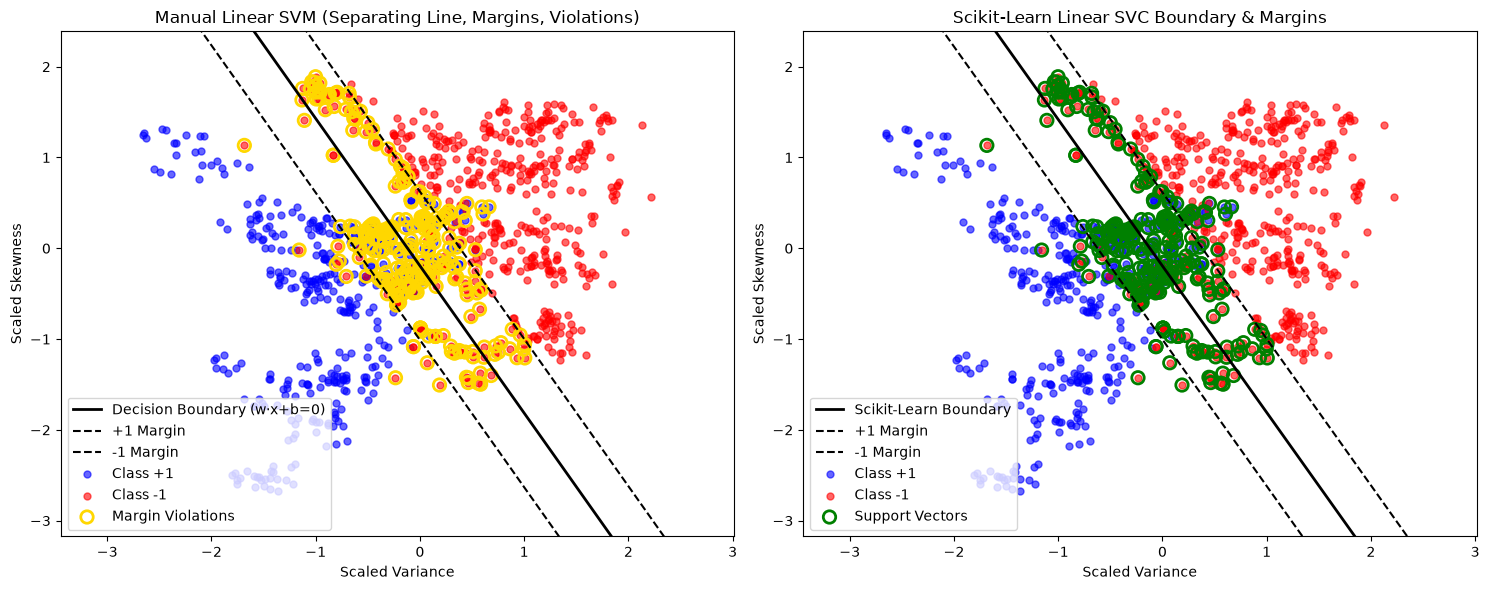

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Manual SVM Decision Boundary & Margins
ax = axes[0]
x0_vals = np.linspace(X_train_2d_scaled[:, 0].min() - 0.5, X_train_2d_scaled[:, 0].max() + 0.5, 200)
w = manual_svm.w
b = manual_svm.b

# w0*x0 + w1*x1 + b = 0 => x1 = (-w0*x0 - b) / w1
hyperplane = (-w[0] * x0_vals - b) / w[1]
margin_pos = (-w[0] * x0_vals - b + 1) / w[1]
margin_neg = (-w[0] * x0_vals - b - 1) / w[1]

# Identify margin violations: y_i * (w^T x_i + b) < 1
functional_margins = y_train_svm * manual_svm.decision_function(X_train_2d_scaled)
violations = functional_margins < 1.0

ax.plot(x0_vals, hyperplane, 'k-', lw=2, label='Decision Boundary (w·x+b=0)')
ax.plot(x0_vals, margin_pos, 'k--', label='+1 Margin')
ax.plot(x0_vals, margin_neg, 'k--', label='-1 Margin')

ax.scatter(X_train_2d_scaled[y_train_svm == 1, 0], X_train_2d_scaled[y_train_svm == 1, 1], c='blue', s=25, alpha=0.6, label='Class +1')
ax.scatter(X_train_2d_scaled[y_train_svm == -1, 0], X_train_2d_scaled[y_train_svm == -1, 1], c='red', s=25, alpha=0.6, label='Class -1')
ax.scatter(X_train_2d_scaled[violations, 0], X_train_2d_scaled[violations, 1], s=80, facecolors='none', edgecolors='gold', lw=2, label='Margin Violations')

ax.set_ylim(X_train_2d_scaled[:, 1].min() - 0.5, X_train_2d_scaled[:, 1].max() + 0.5)
ax.set_title('Manual Linear SVM (Separating Line, Margins, Violations)')
ax.set_xlabel('Scaled Variance')
ax.set_ylabel('Scaled Skewness')
ax.legend(loc='lower left')

# 2. Scikit-Learn Linear SVM Decision Boundary
ax = axes[1]
w_sk = sk_svm.coef_[0]
b_sk = sk_svm.intercept_[0]
hyperplane_sk = (-w_sk[0] * x0_vals - b_sk) / w_sk[1]
margin_pos_sk = (-w_sk[0] * x0_vals - b_sk + 1) / w_sk[1]
margin_neg_sk = (-w_sk[0] * x0_vals - b_sk - 1) / w_sk[1]

ax.plot(x0_vals, hyperplane_sk, 'k-', lw=2, label='Scikit-Learn Boundary')
ax.plot(x0_vals, margin_pos_sk, 'k--', label='+1 Margin')
ax.plot(x0_vals, margin_neg_sk, 'k--', label='-1 Margin')
ax.scatter(X_train_2d_scaled[y_train_svm == 1, 0], X_train_2d_scaled[y_train_svm == 1, 1], c='blue', s=25, alpha=0.6, label='Class +1')
ax.scatter(X_train_2d_scaled[y_train_svm == -1, 0], X_train_2d_scaled[y_train_svm == -1, 1], c='red', s=25, alpha=0.6, label='Class -1')
ax.scatter(sk_svm.support_vectors_[:, 0], sk_svm.support_vectors_[:, 1], s=80, facecolors='none', edgecolors='green', lw=2, label='Support Vectors')

ax.set_ylim(X_train_2d_scaled[:, 1].min() - 0.5, X_train_2d_scaled[:, 1].max() + 0.5)
ax.set_title('Scikit-Learn Linear SVC Boundary & Margins')
ax.set_xlabel('Scaled Variance')
ax.set_ylabel('Scaled Skewness')
ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

### Hyperparameter Sensitivity Analysis (C, Learning Rate, Iterations)

In [9]:
param_grid = [
    {'C': 0.01, 'lr': 0.001, 'iters': 1000},
    {'C': 0.1,  'lr': 0.001, 'iters': 1000},
    {'C': 1.0,  'lr': 0.001, 'iters': 1000},
    {'C': 10.0, 'lr': 0.001, 'iters': 1000},
    {'C': 1.0,  'lr': 0.01,  'iters': 500},
    {'C': 1.0,  'lr': 0.0001,'iters': 3000},
]

svm_study = []
for p in param_grid:
    m_svm = ScratchLinearSVM(lr=p['lr'], C=p['C'], n_iters=p['iters'])
    m_svm.fit(X_train_2d_scaled, y_train_svm)
    preds = m_svm.predict(X_test_2d_scaled)
    acc = accuracy_score(y_test_svm, preds)
    svm_study.append({
        'C': p['C'],
        'Learning Rate': p['lr'],
        'Iterations': p['iters'],
        'Test Accuracy': acc
    })

print(pd.DataFrame(svm_study).to_string(index=False))

    C  Learning Rate  Iterations  Test Accuracy
 0.01         0.0010        1000       0.888350
 0.10         0.0010        1000       0.878641
 1.00         0.0010        1000       0.881068
10.00         0.0010        1000       0.878641
 1.00         0.0100         500       0.878641
 1.00         0.0001        3000       0.881068


--- 
## Part C - Kernel SVM and Nonlinear Boundaries

- Synthetic 2D nonlinear dataset using `make_moons`.
- Train Scikit-learn SVM with Linear, Polynomial, and RBF kernels.
- Compare decision boundaries and analyze kernel projection behavior.

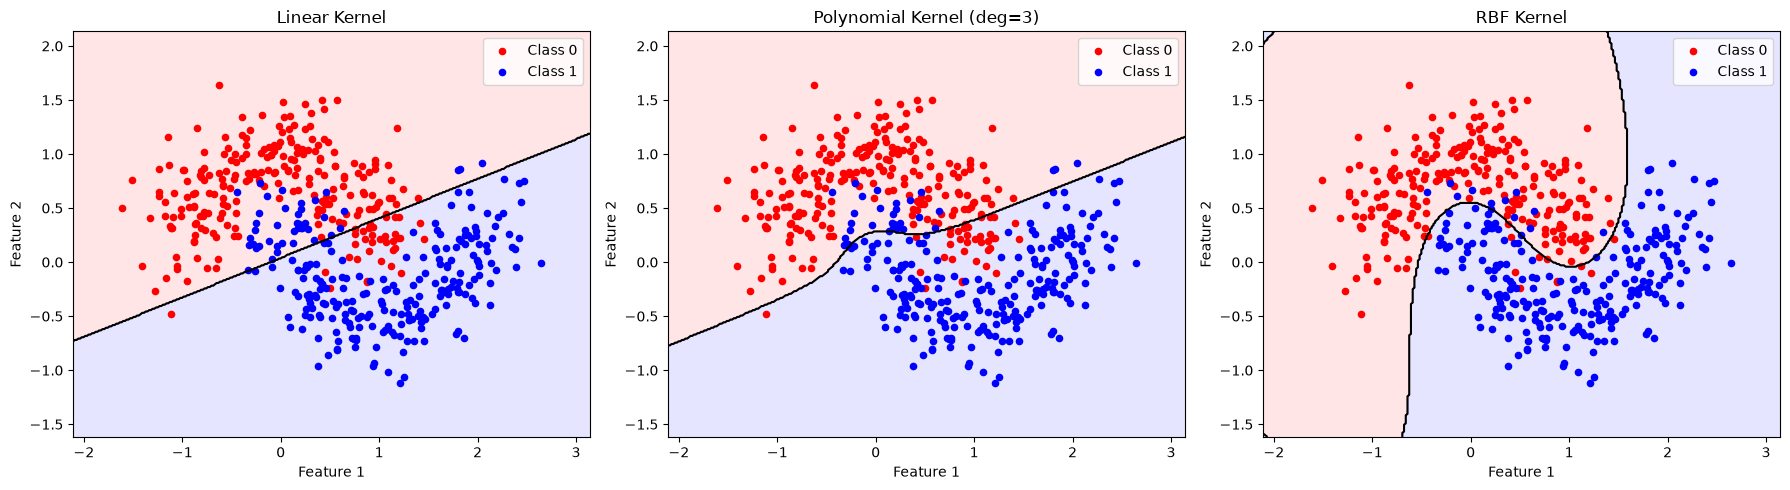

In [10]:
X_moon, y_moon = make_moons(n_samples=500, noise=0.25, random_state=42)

svm_linear = SVC(kernel='linear', C=1.0)
svm_poly = SVC(kernel='poly', degree=3, C=1.0)
svm_rbf = SVC(kernel='rbf', gamma='scale', C=1.0)

models = [('Linear Kernel', svm_linear), ('Polynomial Kernel (deg=3)', svm_poly), ('RBF Kernel', svm_rbf)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x_min, x_max = X_moon[:, 0].min() - 0.5, X_moon[:, 0].max() + 0.5
y_min, y_max = X_moon[:, 1].min() - 0.5, X_moon[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

for ax, (title, clf) in zip(axes, models):
    clf.fit(X_moon, y_moon)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(['#FFAAAA', '#AAAAFF']))
    ax.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=1.5)
    ax.scatter(X_moon[y_moon == 0, 0], X_moon[y_moon == 0, 1], c='red', s=20, label='Class 0')
    ax.scatter(X_moon[y_moon == 1, 0], X_moon[y_moon == 1, 1], c='blue', s=20, label='Class 1')
    ax.set_title(title)
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.legend()

plt.tight_layout()
plt.show()

### Why Nonlinear Kernels Help:
- **Linear Kernel:** Incapable of separating intertwined, non-convex manifolds (such as concentric circles or interleaving moons) without causing high underfitting and low margin clearance.
- **Polynomial Kernel:** Projects points implicitly to a higher-dimensional polynomial feature space, creating curved boundaries.
- **RBF (Radial Basis Function) Kernel:** Projects data into an infinite-dimensional Hilbert space through localized Gaussian kernels, constructing smooth and arbitrarily flexible decision envelopes perfectly adapted to complex non-linear topologies.

--- 
## Part D - Final Full-Dataset Comparison (4 Features)

Train and evaluate all 5 models using all 4 Banknote features:
1. Manual Decision Tree
2. Scikit-learn Decision Tree
3. Manual Linear SVM
4. Scikit-learn Linear SVM
5. Scikit-learn RBF SVM

In [11]:
X_all = df[['variance', 'skewness', 'curtosis', 'entropy']].values
y_all = df['class'].values

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42, stratify=y_all
)

# Standardization for SVMs
full_mean = X_train_full.mean(axis=0)
full_std = X_train_full.std(axis=0)

X_train_full_scaled = (X_train_full - full_mean) / full_std
X_test_full_scaled = (X_test_full - full_mean) / full_std

# Labels for SVMs {-1, 1}
y_train_full_svm = np.where(y_train_full == 0, -1, 1)
y_test_full_svm = np.where(y_test_full == 0, -1, 1)

In [12]:
benchmark_results = []

# 1. Manual Decision Tree
t0 = time.time()
m_dt = ScratchDecisionTreeClassifier(criterion='gini', max_depth=5)
m_dt.fit(X_train_full, y_train_full)
m_dt_train_time = time.time() - t0

t0 = time.time()
m_dt_preds = m_dt.predict(X_test_full)
m_dt_pred_time = time.time() - t0

benchmark_results.append({
    'Model': 'Manual Decision Tree',
    'Accuracy': accuracy_score(y_test_full, m_dt_preds),
    'Precision': precision_score(y_test_full, m_dt_preds),
    'Recall': recall_score(y_test_full, m_dt_preds),
    'F1-Score': f1_score(y_test_full, m_dt_preds),
    'Train Time (s)': m_dt_train_time,
    'Pred Time (s)': m_dt_pred_time
})

# 2. Scikit-Learn Decision Tree
t0 = time.time()
sk_dt = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
sk_dt.fit(X_train_full, y_train_full)
sk_dt_train_time = time.time() - t0

t0 = time.time()
sk_dt_preds = sk_dt.predict(X_test_full)
sk_dt_pred_time = time.time() - t0

benchmark_results.append({
    'Model': 'Sklearn Decision Tree',
    'Accuracy': accuracy_score(y_test_full, sk_dt_preds),
    'Precision': precision_score(y_test_full, sk_dt_preds),
    'Recall': recall_score(y_test_full, sk_dt_preds),
    'F1-Score': f1_score(y_test_full, sk_dt_preds),
    'Train Time (s)': sk_dt_train_time,
    'Pred Time (s)': sk_dt_pred_time
})

# 3. Manual Linear SVM
t0 = time.time()
m_svm = ScratchLinearSVM(lr=0.001, C=1.0, n_iters=2500)
m_svm.fit(X_train_full_scaled, y_train_full_svm)
m_svm_train_time = time.time() - t0

t0 = time.time()
m_svm_preds_raw = m_svm.predict(X_test_full_scaled)
m_svm_pred_time = time.time() - t0
m_svm_preds = np.where(m_svm_preds_raw == -1, 0, 1)

benchmark_results.append({
    'Model': 'Manual Linear SVM',
    'Accuracy': accuracy_score(y_test_full, m_svm_preds),
    'Precision': precision_score(y_test_full, m_svm_preds),
    'Recall': recall_score(y_test_full, m_svm_preds),
    'F1-Score': f1_score(y_test_full, m_svm_preds),
    'Train Time (s)': m_svm_train_time,
    'Pred Time (s)': m_svm_pred_time
})

# 4. Scikit-Learn Linear SVM
t0 = time.time()
sk_lsvm = SVC(kernel='linear', C=1.0)
sk_lsvm.fit(X_train_full_scaled, y_train_full)
sk_lsvm_train_time = time.time() - t0

t0 = time.time()
sk_lsvm_preds = sk_lsvm.predict(X_test_full_scaled)
sk_lsvm_pred_time = time.time() - t0

benchmark_results.append({
    'Model': 'Sklearn Linear SVM',
    'Accuracy': accuracy_score(y_test_full, sk_lsvm_preds),
    'Precision': precision_score(y_test_full, sk_lsvm_preds),
    'Recall': recall_score(y_test_full, sk_lsvm_preds),
    'F1-Score': f1_score(y_test_full, sk_lsvm_preds),
    'Train Time (s)': sk_lsvm_train_time,
    'Pred Time (s)': sk_lsvm_pred_time
})

# 5. Scikit-Learn RBF SVM
t0 = time.time()
sk_rbf = SVC(kernel='rbf', C=1.0, gamma='scale')
sk_rbf.fit(X_train_full_scaled, y_train_full)
sk_rbf_train_time = time.time() - t0

t0 = time.time()
sk_rbf_preds = sk_rbf.predict(X_test_full_scaled)
sk_rbf_pred_time = time.time() - t0

benchmark_results.append({
    'Model': 'Sklearn RBF SVM',
    'Accuracy': accuracy_score(y_test_full, sk_rbf_preds),
    'Precision': precision_score(y_test_full, sk_rbf_preds),
    'Recall': recall_score(y_test_full, sk_rbf_preds),
    'F1-Score': f1_score(y_test_full, sk_rbf_preds),
    'Train Time (s)': sk_rbf_train_time,
    'Pred Time (s)': sk_rbf_pred_time
})

df_final = pd.DataFrame(benchmark_results)
print(df_final.to_string(index=False))

                Model  Accuracy  Precision   Recall  F1-Score  Train Time (s)  Pred Time (s)
 Manual Decision Tree  0.980583   0.983425 0.972678  0.978022       13.058666       0.002995
Sklearn Decision Tree  0.985437   0.973262 0.994536  0.983784        0.028024       0.002334
    Manual Linear SVM  0.980583   0.958115 1.000000  0.978610       82.437756       0.002001
   Sklearn Linear SVM  0.980583   0.958115 1.000000  0.978610        0.036875       0.009083
      Sklearn RBF SVM  1.000000   1.000000 1.000000  1.000000        0.033909       0.033900


### Performance Metric Visualizations

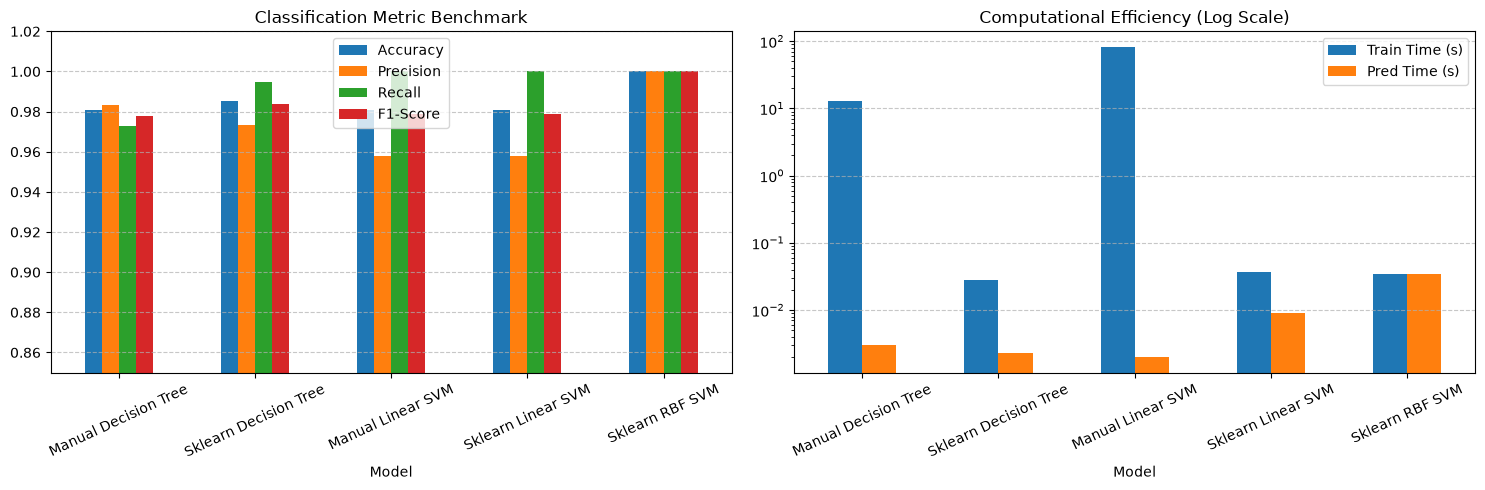

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

df_final.plot(x='Model', y=['Accuracy', 'Precision', 'Recall', 'F1-Score'], kind='bar', ax=ax[0], rot=25)
ax[0].set_ylim(0.85, 1.02)
ax[0].set_title('Classification Metric Benchmark')
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

df_final.plot(x='Model', y=['Train Time (s)', 'Pred Time (s)'], kind='bar', ax=ax[1], rot=25, logy=True)
ax[1].set_title('Computational Efficiency (Log Scale)')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Discussion & Performance Analysis

### 1. Interpretability
- **Decision Trees:** Highly interpretable. The nested `if-else` threshold rules allow human operators to audit precisely which feature combinations (e.g., `variance <= -0.42` and `skewness <= 5.12`) trigger counterfeit classification.
- **Linear SVM:** Moderately interpretable via the weight vector $\mathbf{w}$. The magnitude and signs of coefficients reveal the relative importance and directional influence of each feature.
- **RBF SVM:** Black-box nature. Non-linear kernel mapping into infinite dimensions prohibits direct inspection of decision paths.

### 2. Feature Scaling Sensitivity
- **Decision Trees:** Invariant to monotonic feature scaling because split points depend only on feature rank-ordering, not magnitudes.
- **SVM Models:** Extremely sensitive to scale. SVM solves a convex margin maximization problem where the margin width $\frac{2}{\|\mathbf{w}\|}$ is directly dependent on Euclidean distances. Unscaled features with larger ranges would unfairly dominate the objective function.

### 3. Overfitting & Model Complexity
- **Decision Trees:** Prone to severe overfitting when `max_depth` is unrestricted, memorizing training samples through leaf fragmentation.
- **Linear SVM:** High bias, low variance. It provides strong regularization against overfitting through the soft-margin penalty $C$.
- **RBF SVM:** Can overfit if $\gamma$ is too high (creating tight boundary 'islands' around individual training points) or underfit if $\gamma$ is too small.